In [ ]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import (precision_recall_curve, average_precision_score,
                             precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay)

X_train = pd.read_csv("../data/X_train.csv")
y_train = pd.read_csv("../data/y_train.csv")["Class"]
X_test = pd.read_csv("../data/X_test.csv")
y_test = pd.read_csv("../data/y_test.csv")["Class"]

model = joblib.load("../models/best_model.pkl")
print(type(model).__name__)

XGBClassifier


In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

oof_prob = cross_val_predict(clone(model), X_train, y_train,
                             cv=cv, method="predict_proba")[:, 1]

print("PR-AUC (out-of-fold):", round(average_precision_score(y_train, oof_prob), 4))

PR-AUC (out-of-fold): 0.8432


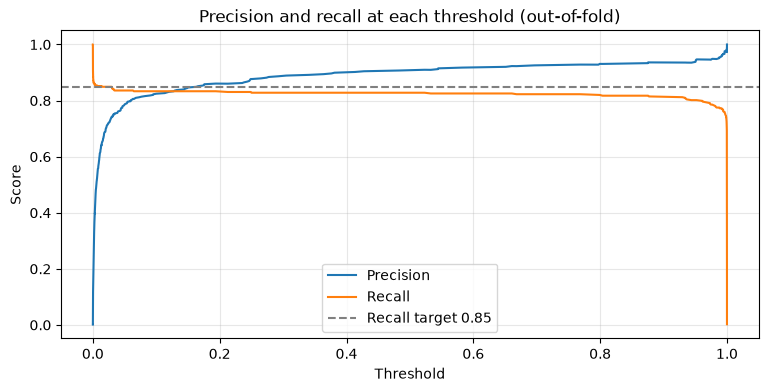

In [ ]:
prec, rec, thr = precision_recall_curve(y_train, oof_prob)
prec, rec = prec[:-1], rec[:-1]

plt.figure(figsize=(9, 4))
plt.plot(thr, prec, label="Precision")
plt.plot(thr, rec, label="Recall")
plt.axhline(0.85, color="grey", linestyle="--", label="Recall target 0.85")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Precision and recall at each threshold (out-of-fold)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [ ]:
rows = []
for t in [0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
    pred = (oof_prob >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_train, pred).ravel()
    rows.append({"Threshold": t, "Fraud caught": tp, "Fraud missed": fn,
                 "False alarms": fp,
                 "Precision": round(precision_score(y_train, pred), 3),
                 "Recall": round(recall_score(y_train, pred), 3),
                 "F1": round(f1_score(y_train, pred), 3)})
pd.DataFrame(rows).set_index("Threshold")

,Fraud caught,Fraud missed,False alarms,Precision,Recall,F1
Threshold,,,,,,
0.05,316,62,86,0.786,0.836,0.810
0.10,315,63,67,0.825,0.833,0.829
0.20,314,64,51,0.860,0.831,0.845
0.30,313,65,39,0.889,0.828,0.858
0.40,313,65,34,0.902,0.828,0.863
0.50,313,65,31,0.910,0.828,0.867
0.60,312,66,27,0.920,0.825,0.870
0.70,311,67,24,0.928,0.823,0.872
0.80,309,69,23,0.931,0.817,0.870


In [ ]:
target_recall = 0.85

ok = rec >= target_recall
best_i = np.argmax(np.where(ok, prec, -1))
chosen = float(thr[best_i])

f1 = 2 * prec * rec / (prec + rec + 1e-9)
f1_thr = float(thr[f1.argmax()])

print(f"Threshold for recall ≥ {target_recall}: {chosen:.3f}  "
      f"(precision {prec[best_i]:.3f}, recall {rec[best_i]:.3f})")
print(f"Threshold with best F1:          {f1_thr:.3f}  (F1 {f1.max():.3f})")

Threshold for recall ≥ 0.85: 0.014  (precision 0.641, recall 0.852)
Threshold with best F1:          0.876  (F1 0.873)


Test PR-AUC: 0.8263
Default 0.5    → caught 72/95, missed 23, false alarms 5, precision 0.935, recall 0.758, F1 0.837
Tuned 0.014    → caught 78/95, missed 17, false alarms 45, precision 0.634, recall 0.821, F1 0.716


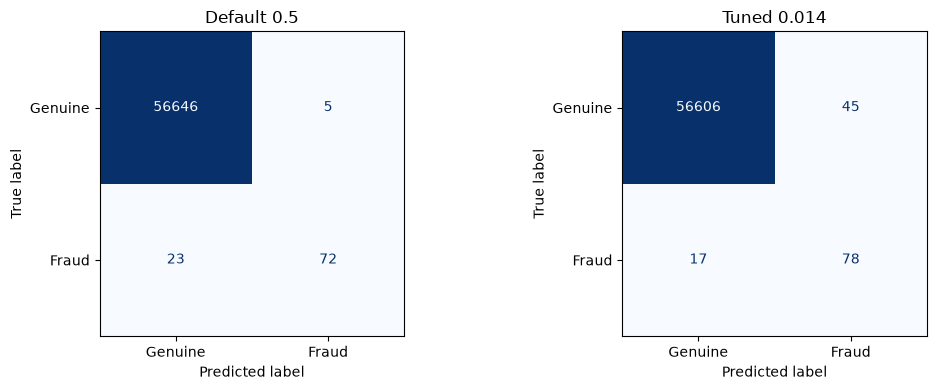

In [ ]:
test_prob = model.predict_proba(X_test)[:, 1]
print("Test PR-AUC:", round(average_precision_score(y_test, test_prob), 4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, t, label in [(axes[0], 0.5, "Default 0.5"), (axes[1], chosen, f"Tuned {chosen:.3f}")]:
    pred = (test_prob >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    print(f"{label:14} → caught {tp}/{tp+fn}, missed {fn}, false alarms {fp}, "
          f"precision {precision_score(y_test, pred):.3f}, recall {recall_score(y_test, pred):.3f}, "
          f"F1 {f1_score(y_test, pred):.3f}")
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred),
                           display_labels=["Genuine", "Fraud"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(label)
plt.tight_layout()
plt.show()

In [ ]:
with open("../models/threshold.json", "w") as f:
    json.dump({"threshold": chosen, "target_recall": target_recall}, f, indent=2)
print("Saved threshold:", round(chosen, 3))

Saved threshold: 0.014


## Final results (held-out test set, used once)
- Test PR-AUC 0.826 (CV estimate 0.843) → the CV estimate was reliable.
- Default threshold 0.5: caught 72/95 frauds, 5 false alarms (precision 0.935, recall 0.758).
- Tuned threshold 0.014 (chosen on out-of-fold predictions for recall ≥ 0.85): caught 78/95, 45 false alarms (precision 0.634, recall 0.821).
- Recall plateaus at ~0.83 across thresholds 0.05–0.9: ~17% of frauds look genuine to the model, so threshold tuning gives little extra recall at a large precision cost. Better features (e.g. cardholder history) are needed to catch them.
- App design: two risk levels — high risk at ≥ 0.5, "check this" at ≥ 0.014.